<a href="https://colab.research.google.com/github/ChodaPendulum/RET503---P2-Transfer-Learning/blob/main/MobileNet_SSDLite_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer Learning MobileNet-SSD (SSDLite320 MobileNetV3) dengan PyTorch

Melatih **SSDLite320 + MobileNetV3-Large** (pre-trained COCO, dari torchvision) untuk mendeteksi *person*
memakai dataset Roboflow [Person v3 (MODD2)](https://universe.roboflow.com/modd2/person-bmcxg/dataset/3) format **COCO JSON**.

Transfer learning: seluruh bobot COCO dipakai ulang, lalu **head klasifikasi diganti** sesuai jumlah kelas dataset Anda.

**Langkah kerja:**
1. **Runtime → Change runtime type → T4 GPU**.
2. Siapkan **API key Roboflow** (Roboflow → Settings → API Keys).
3. Jalankan cell dari atas ke bawah.

## 1. Cek GPU

In [1]:
!nvidia-smi
import torch, torchvision
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| CUDA:", torch.cuda.is_available())

Sat Oct 10 00:00:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Folder kerja (Google Drive)

In [2]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = "/content/drive/MyDrive/mobilenet_ssd_person_pt"
    print("Drive berhasil terhubung.")
except Exception as e:
    print("Drive gagal dimount, memakai penyimpanan lokal sementara:", e)
    WORK_DIR = "/content/work"

os.makedirs(WORK_DIR, exist_ok=True)
print("Folder kerja:", WORK_DIR)

Mounted at /content/drive
Drive berhasil terhubung.
Folder kerja: /content/drive/MyDrive/mobilenet_ssd_person_pt


## 3. Install library tambahan

In [3]:
!pip install -q roboflow torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 100.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.6 MB/s eta 0:00:00


## 4. Download dataset (format COCO JSON)

In [4]:
from getpass import getpass
from roboflow import Roboflow

api_key = getpass("Masukkan API key Roboflow: ")
rf = Roboflow(api_key=api_key)
project = rf.workspace("modd2").project("person-bmcxg")
dataset = project.version(3).download("coco", location="/content/Person-3-coco")
DATA = dataset.location
print("Dataset di:", DATA)
!ls {DATA}

Masukkan API key Roboflow: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/Person-3-coco in coco:: 100%|██████████| 959/959 [00:00<00:00, 9226.43it/s]


Dataset di: /content/Person-3-coco
README.dataset.txt  README.roboflow.txt  test  train  valid


## 5. Dataset class

In [5]:
import json, os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

class CocoDet(Dataset):
    """Membaca folder Roboflow COCO: gambar + _annotations.coco.json"""
    def __init__(self, folder, transforms=None):
        self.folder = folder
        self.transforms = transforms
        data = json.load(open(os.path.join(folder, "_annotations.coco.json")))
        self.images = data["images"]
        self.cat_names = {c["id"]: c["name"] for c in data["categories"]}
        self.anns = {}
        for a in data["annotations"]:
            self.anns.setdefault(a["image_id"], []).append(a)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        info = self.images[idx]
        img = Image.open(os.path.join(self.folder, info["file_name"])).convert("RGB")
        boxes, labels = [], []
        for a in self.anns.get(info["id"], []):
            x, y, w, h = a["bbox"]
            if w > 1 and h > 1:
                boxes.append([x, y, x + w, y + h])
                labels.append(self.label_map[a["category_id"]])
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        target = {
            "boxes": tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=(img.height, img.width)),
            "labels": torch.tensor(labels, dtype=torch.int64),
        }
        if self.transforms:
            img, target = self.transforms(img, target)
        return img, target

train_dir, valid_dir, test_dir = [os.path.join(DATA, s) for s in ("train", "valid", "test")]

# Pemetaan id kategori -> 1..N (0 = background). Hanya kategori yang benar-benar dipakai anotasi.
raw = json.load(open(os.path.join(train_dir, "_annotations.coco.json")))
used_ids = sorted({a["category_id"] for a in raw["annotations"]})
names = {c["id"]: c["name"] for c in raw["categories"]}
LABEL_MAP = {cid: i + 1 for i, cid in enumerate(used_ids)}
CLASS_NAMES = ["__background__"] + [names[c] for c in used_ids]
NUM_CLASSES = len(CLASS_NAMES)          # termasuk background
print("Kelas:", CLASS_NAMES)

CocoDet.label_map = LABEL_MAP

train_tf = T.Compose([
    T.ToImage(),
    T.RandomHorizontalFlip(0.5),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.ToDtype(torch.float32, scale=True),
    T.SanitizeBoundingBoxes(),
])
eval_tf = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_ds = CocoDet(train_dir, train_tf)
valid_ds = CocoDet(valid_dir, eval_tf)
test_ds  = CocoDet(test_dir,  eval_tf)
print(f"train={len(train_ds)}  valid={len(valid_ds)}  test={len(test_ds)}")

BATCH_SIZE = 16
collate = lambda b: tuple(zip(*b))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, collate_fn=collate)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, collate_fn=collate)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, collate_fn=collate)

Kelas: ['__background__', 'person', 'person-like']
train=854  valid=64  test=33


## 6. Bangun model (transfer learning)

Model dimuat dengan bobot COCO, lalu classification head diganti agar jumlah kelasnya sesuai dataset.

In [6]:
from functools import partial
import torch.nn as nn
from torchvision.models.detection import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights
from torchvision.models.detection.ssdlite import SSDLiteClassificationHead
from torchvision.models.detection import _utils as det_utils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ssdlite320_mobilenet_v3_large(weights=SSDLite320_MobileNet_V3_Large_Weights.COCO_V1)

in_channels = det_utils.retrieve_out_channels(model.backbone, (320, 320))
num_anchors = model.anchor_generator.num_anchors_per_location()
norm_layer = partial(nn.BatchNorm2d, eps=0.001, momentum=0.03)
model.head.classification_head = SSDLiteClassificationHead(in_channels, num_anchors, NUM_CLASSES, norm_layer)

# Opsional: bekukan backbone agar training lebih cepat/stabil di dataset kecil
FREEZE_BACKBONE = False
if FREEZE_BACKBONE:
    for p in model.backbone.parameters():
        p.requires_grad = False

model.to(device)
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameter yang dilatih: {n_train/1e6:.2f} juta")

Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 69.8MB/s]


Parameter yang dilatih: 2.22 juta


## 7. Training + evaluasi tiap epoch (model terbaik disimpan otomatis)

In [7]:
import time, math
from torchmetrics.detection.mean_ap import MeanAveragePrecision

EPOCHS = 30
LR = 0.01

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=4e-5)
total_iters = EPOCHS * len(train_loader)
warmup_iters = len(train_loader)          # warmup 1 epoch
def lr_lambda(it):
    if it < warmup_iters:
        return 0.1 + 0.9 * it / warmup_iters
    p = (it - warmup_iters) / max(1, total_iters - warmup_iters)
    return 0.5 * (1 + math.cos(math.pi * p))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

@torch.no_grad()
def evaluate(loader):
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    for imgs, tgts in loader:
        imgs = [i.to(device) for i in imgs]
        outs = model(imgs)
        preds = [{k: v.cpu() for k, v in o.items()} for o in outs]
        gts = [{"boxes": t["boxes"].as_subclass(torch.Tensor), "labels": t["labels"]} for t in tgts]
        metric.update(preds, gts)
    r = metric.compute()
    return float(r["map"]), float(r["map_50"])

best_map50 = -1
BEST_PATH = f"{WORK_DIR}/best_ssdlite_person.pth"
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, run_loss = time.time(), 0.0
    for imgs, tgts in train_loader:
        imgs = [i.to(device) for i in imgs]
        tgts = [{"boxes": t["boxes"].as_subclass(torch.Tensor).to(device), "labels": t["labels"].to(device)} for t in tgts]
        losses = model(imgs, tgts)
        loss = sum(losses.values())
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params, 10.0)
        optimizer.step()
        scheduler.step()
        run_loss += loss.item()
    m, m50 = evaluate(valid_loader)
    history.append((epoch, run_loss / len(train_loader), m, m50))
    flag = ""
    if m50 > best_map50:
        best_map50 = m50
        torch.save({"model": model.state_dict(), "classes": CLASS_NAMES}, BEST_PATH)
        flag = "  <- terbaik, disimpan"
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss {run_loss/len(train_loader):.3f} | "
          f"val mAP {m:.3f} | mAP@0.5 {m50:.3f} | {time.time()-t0:.0f}s{flag}")

print("Selesai. mAP@0.5 validasi terbaik:", round(best_map50, 3))

Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.


Epoch 01/30 | loss 4.871 | val mAP 0.232 | mAP@0.5 0.428 | 30s  <- terbaik, disimpan
Epoch 02/30 | loss 3.170 | val mAP 0.340 | mAP@0.5 0.603 | 29s  <- terbaik, disimpan
Epoch 03/30 | loss 2.496 | val mAP 0.442 | mAP@0.5 0.725 | 29s  <- terbaik, disimpan
Epoch 04/30 | loss 2.236 | val mAP 0.460 | mAP@0.5 0.769 | 28s  <- terbaik, disimpan
Epoch 05/30 | loss 1.978 | val mAP 0.419 | mAP@0.5 0.681 | 27s
Epoch 06/30 | loss 1.762 | val mAP 0.466 | mAP@0.5 0.767 | 28s
Epoch 07/30 | loss 1.639 | val mAP 0.495 | mAP@0.5 0.815 | 28s  <- terbaik, disimpan
Epoch 08/30 | loss 1.465 | val mAP 0.490 | mAP@0.5 0.836 | 28s  <- terbaik, disimpan
Epoch 09/30 | loss 1.293 | val mAP 0.471 | mAP@0.5 0.794 | 31s
Epoch 10/30 | loss 1.181 | val mAP 0.510 | mAP@0.5 0.830 | 30s
Epoch 11/30 | loss 1.091 | val mAP 0.515 | mAP@0.5 0.828 | 29s
Epoch 12/30 | loss 0.942 | val mAP 0.521 | mAP@0.5 0.851 | 28s  <- terbaik, disimpan
Epoch 13/30 | loss 0.884 | val mAP 0.527 | mAP@0.5 0.823 | 27s
Epoch 14/30 | loss 0.800 | 

### Grafik loss dan mAP

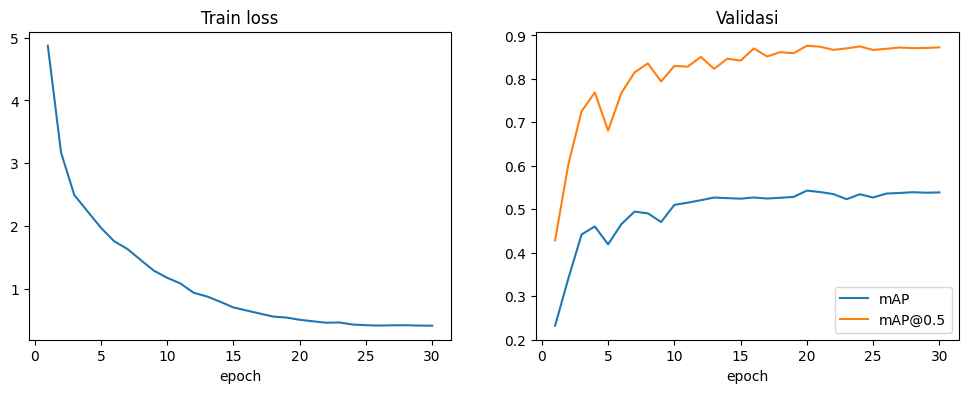

In [8]:
import matplotlib.pyplot as plt
ep = [h[0] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, [h[1] for h in history]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(ep, [h[2] for h in history], label="mAP"); ax[1].plot(ep, [h[3] for h in history], label="mAP@0.5")
ax[1].set_title("Validasi"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 8. Evaluasi akhir pada data test (model terbaik)

In [9]:
ckpt = torch.load(BEST_PATH, map_location=device)
model.load_state_dict(ckpt["model"])
m, m50 = evaluate(test_loader)
print(f"TEST  mAP: {m:.3f} | mAP@0.5: {m50:.3f}")

TEST  mAP: 0.571 | mAP@0.5: 0.926


## 9. Visualisasi hasil deteksi

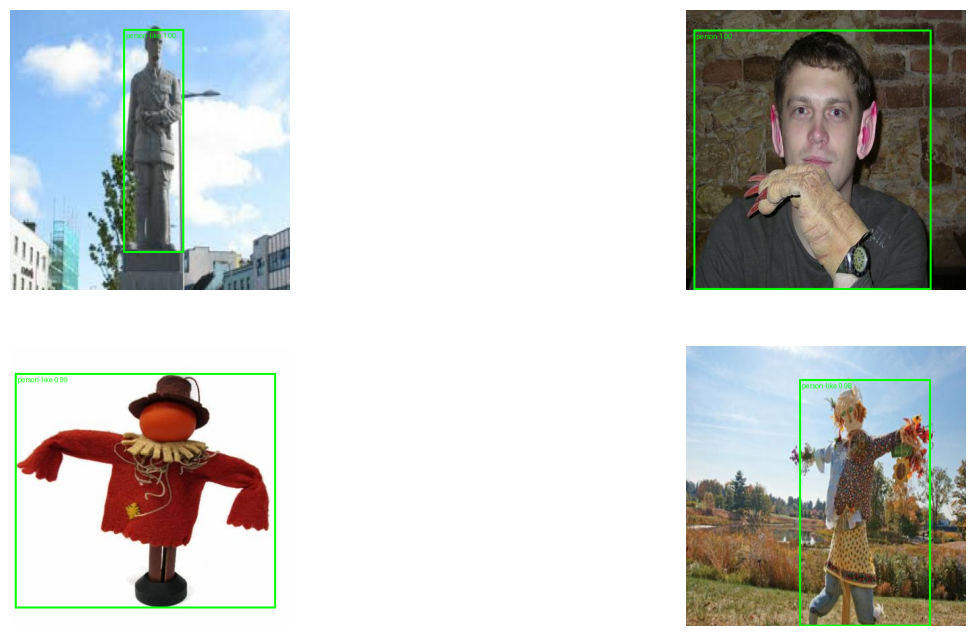

In [10]:
from torchvision.utils import draw_bounding_boxes
import matplotlib.pyplot as plt

@torch.no_grad()
def predict(img_tensor, thresh=0.5):
    model.eval()
    out = model([img_tensor.to(device)])[0]
    keep = out["scores"] >= thresh
    return out["boxes"][keep].cpu(), out["labels"][keep].cpu(), out["scores"][keep].cpu()

def draw(img_tensor, thresh=0.5):
    boxes, labels, scores = predict(img_tensor, thresh)
    caps = [f"{CLASS_NAMES[l]} {s:.2f}" for l, s in zip(labels.tolist(), scores.tolist())]
    img_u8 = (img_tensor * 255).to(torch.uint8)
    return draw_bounding_boxes(img_u8, boxes, caps, colors="lime", width=3).permute(1, 2, 0).numpy()

plt.figure(figsize=(16, 8))
for i in range(4):
    img, _ = test_ds[i]
    plt.subplot(2, 2, i + 1)
    plt.imshow(draw(img)); plt.axis("off")
plt.show()

### Uji dengan gambar sendiri

Saving standing_8_11_23-56-.jpg to standing_8_11_23-56-.jpg
Saving standing_8_11_23-12-.jpg to standing_8_11_23-12-.jpg
Saving 452027284_333156903096510_3528516671533867104_n.jpg to 452027284_333156903096510_3528516671533867104_n.jpg
Saving Capture d’écran 2024-08-03 212702.png to Capture d’écran 2024-08-03 212702.png
Saving standing_8_11_23-60-.jpg to standing_8_11_23-60-.jpg
Saving 451446921_3427163434249445_5744772114897539803_n.jpg to 451446921_3427163434249445_5744772114897539803_n.jpg
Saving 453660380_488720897211753_8907742914275340966_n.jpg to 453660380_488720897211753_8907742914275340966_n.jpg
Saving frame_0399.jpg to frame_0399 (1).jpg


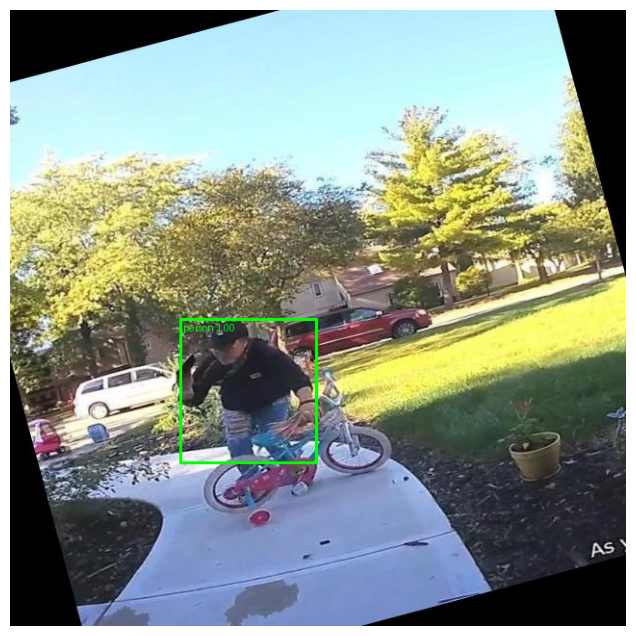

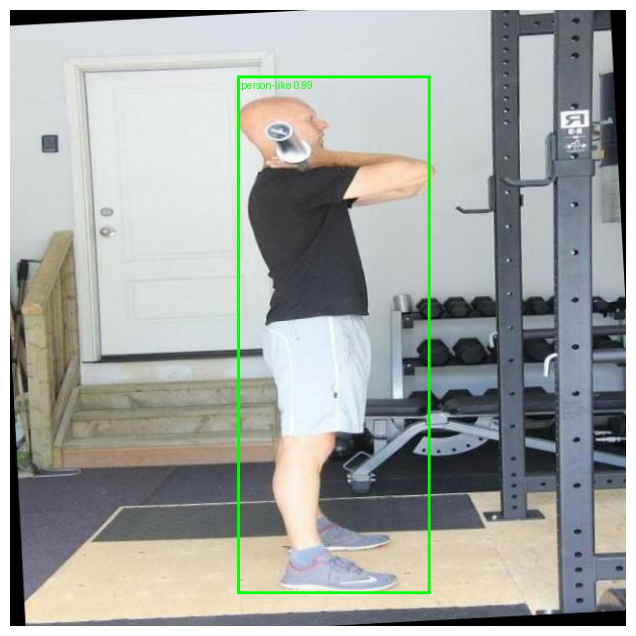

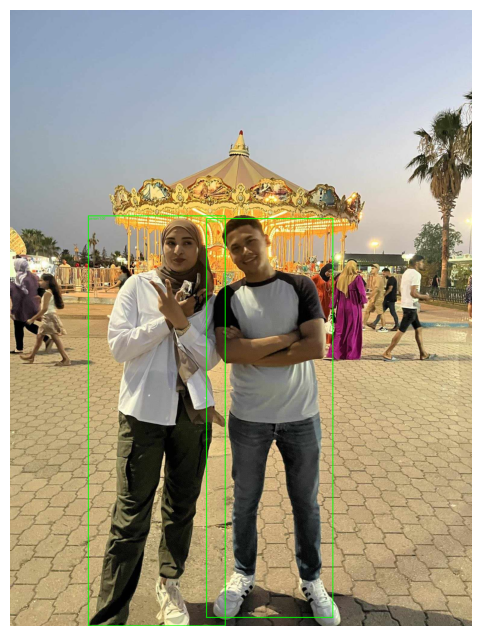

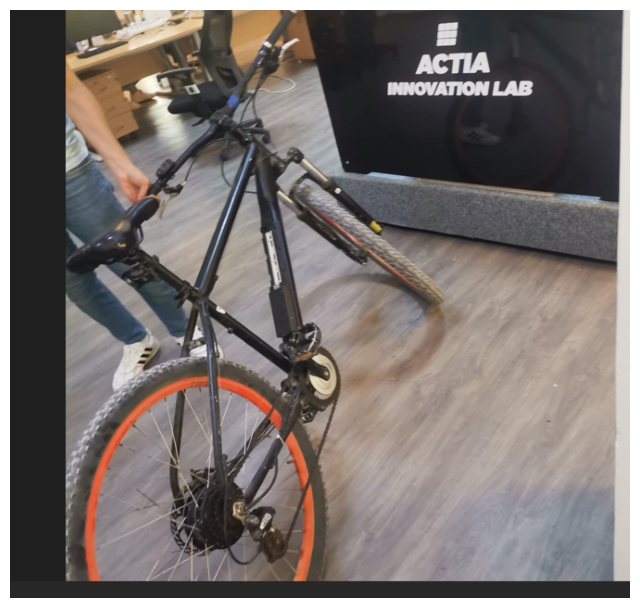

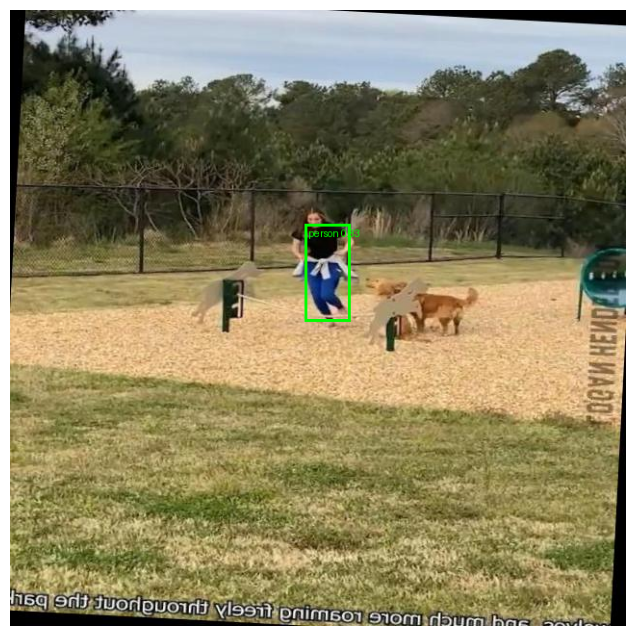

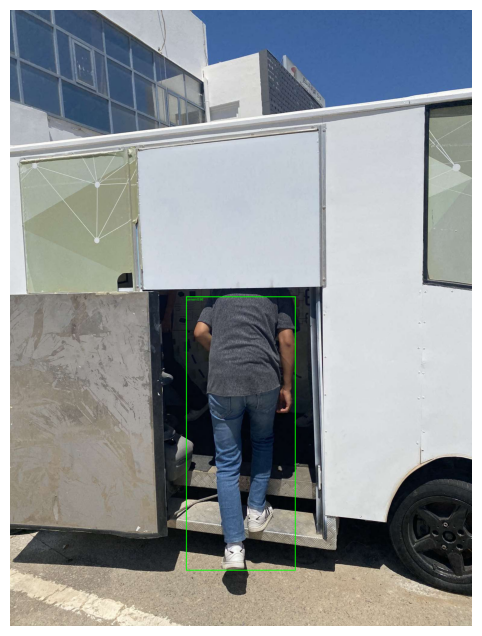

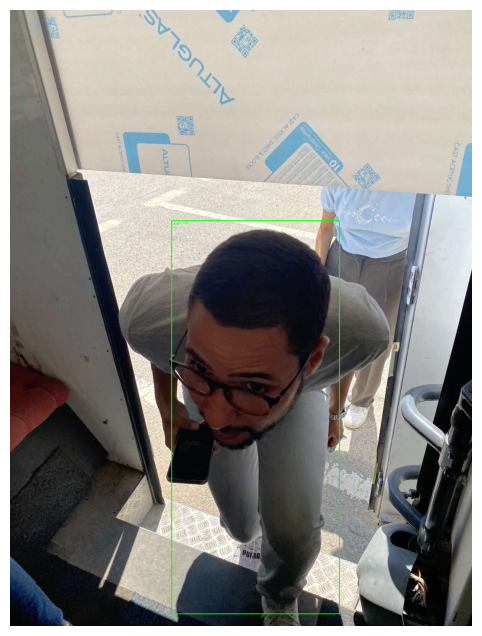

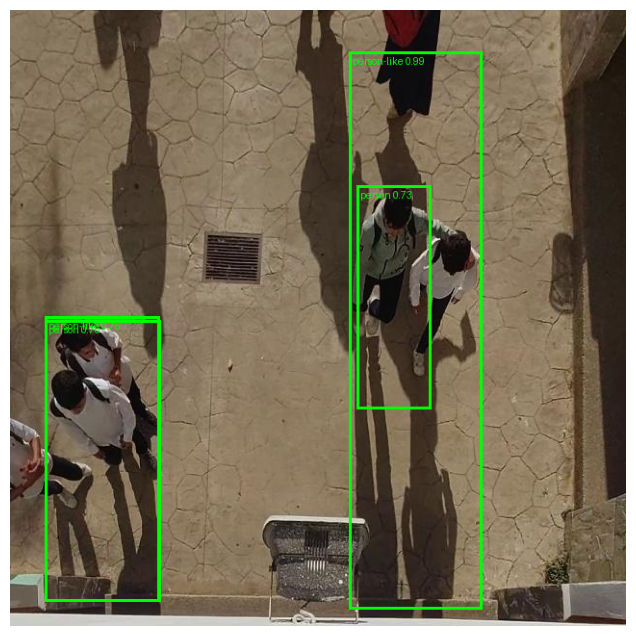

In [13]:
from google.colab import files
import io
up = files.upload()
for name, data in up.items():
    img = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])(Image.open(io.BytesIO(data)).convert("RGB"))
    plt.figure(figsize=(8, 8)); plt.imshow(draw(img)); plt.axis("off"); plt.show()